# Lab 3 (Parcial 2) · Parte II — Análisis de sentimiento en reseñas de IMDB con LSTM

## Objetivo

Clasificar **reseñas de películas** de IMDB como **positivas o negativas** con una red recurrente. Es un problema *muchos a uno*: la red lee la reseña palabra a palabra y al final da **una probabilidad** de que sea positiva. Es clasificación binaria, así que la salida es una sigmoide y la pérdida, la entropía cruzada binaria.

Tarea del enunciado (Parte II):

* Usar un modelo **LSTM** (se permite GRU para acelerar) sobre `IMDB Dataset10M.csv` (10 000 reseñas).
* El código proporcionado (`L3-T2-IMDB_Sentiment_Analysis.ipynb`) trabaja con **embeddings densos** de dos tipos:
  * **aprendidos** (*learnt embeddings*): los pesos del embedding se aprenden durante el entrenamiento;
  * **GloVe** (*GloVe embeddings*): vectores preentrenados con un corpus enorme (`glove.6B.100d.txt`).
* **Mostrar resultados**, analizar **reseñas cercanas al umbral** (probabilidad ≈ 0,5) y cómo se comporta el modelo, **comparar** los dos enfoques y **analizarlos**.

Plan del cuaderno:

1. El código proporcionado, explicado y ejecutado con sus dos opciones de embedding.
2. Diagnóstico: qué falla en el código original (relleno, preprocesado, entrenamiento).
3. Mejoras, medidas con varias semillas en validación.
4. Comparación final de embeddings aprendidos, GloVe congelado y GloVe ajustado (5 semillas, test).
5. Efecto de la cantidad de datos de entrenamiento.
6. Reseñas cercanas al umbral y casos difíciles.
7. Qué han aprendido los embeddings.
8. Conclusiones.

## 0. Preparación del entorno

En Colab basta con subir `IMDB Dataset10M.csv` y `glove.6B.100d.txt` a `/content`; en local se usa la carpeta `data/` del lab y el entorno de `Parcial-2/requirements.txt` (con `nltk` y `tqdm`).

**Dispositivo.** El código original usa CUDA si existe y si no, la CPU; la parte 1 se ejecuta así, tal cual. Para los experimentos se usa la GPU del Mac (**MPS**) si está disponible: una LSTM bidireccional de 2 capas es 4–5 veces más rápida que en la CPU.

In [1]:
%matplotlib inline
import copy
import json
import math
import os
import re
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tqdm import tqdm
from functools import partialmethod
tqdm.__init__ = partialmethod(tqdm.__init__, disable=True)   # sin barras de progreso en el cuaderno guardado

for recurso in ('punkt', 'punkt_tab', 'stopwords'):
    nltk.download(recurso, quiet=True)

LAB_DIR = None
for candidato in (Path.cwd(), Path.cwd() / 'lab3', Path.cwd() / 'Parcial-2' / 'Lab3-LSTM' / 'lab3', Path('/content')):
    if (candidato / 'data').exists() or (candidato / 'IMDB Dataset10M.csv').exists():
        LAB_DIR = candidato
        break
if LAB_DIR is None:
    raise FileNotFoundError('No se encuentra la carpeta del Lab 3 (con data/)')
DATA_DIR = LAB_DIR / 'data' if (LAB_DIR / 'data').exists() else LAB_DIR

RUTA_CSV = DATA_DIR / 'IMDB Dataset10M.csv'
RUTA_GLOVE = DATA_DIR / 'glove.6B.100d.txt'
DISPOSITIVO = torch.device('cuda' if torch.cuda.is_available() else
                           'mps' if torch.backends.mps.is_available() else 'cpu')
torch.set_num_threads(min(4, os.cpu_count()))
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
pd.set_option('display.precision', 4)
pd.set_option('display.max_colwidth', 120)
print('PyTorch', torch.__version__, '| dispositivo de los experimentos:', DISPOSITIVO)
print('CSV:', RUTA_CSV.exists(), '| GloVe:', RUTA_GLOVE.exists())

PyTorch 2.15.0 | dispositivo de los experimentos: mps
CSV: True | GloVe: True


# 1. El código proporcionado, explicado y ejecutado

El código se ejecuta tal cual, con tres cambios que no alteran su comportamiento: las rutas de los archivos, una semilla fija (para poder repetirlo) y las barras de progreso desactivadas.

## 1.1. Datos y partición

10 000 reseñas con su etiqueta (`positive`/`negative`, casi equilibradas). La partición del código es poco habitual: deja el **60 % para test** (6 000 reseñas) y el 40 % restante (4 000) lo divide **a partes iguales** entre entrenamiento y validación: el modelo solo se entrena con **2 000 reseñas**.

In [2]:
imdb_df = pd.read_csv(RUTA_CSV, engine='python', on_bad_lines='warn')
if 'sentiment' in imdb_df.columns and 's' not in imdb_df.columns:
    imdb_df = imdb_df.rename(columns={'sentiment': 's'})
imdb_df['s'] = imdb_df['s'].map({'negative': 0, 'positive': 1})
if 'review' in imdb_df.columns and 'text' not in imdb_df.columns:
    imdb_df = imdb_df.rename(columns={'review': 'text'})

print(f"Total de reseñas: {len(imdb_df)} | positivas: {imdb_df['s'].mean():.1%} | "
      f"reseñas repetidas: {imdb_df['text'].duplicated().sum()}")

# Partición del código: 60 % test; el 40 % restante, 50/50 entrenamiento/validación
train_val_df, test_df = train_test_split(imdb_df, test_size=0.6, random_state=42, stratify=imdb_df['s'])
train_df, val_df = train_test_split(train_val_df, test_size=0.5, random_state=42, stratify=train_val_df['s'])
print(f'entrenamiento {len(train_df)} | validación {len(val_df)} | test {len(test_df)}')
print(imdb_df['text'].iloc[1][:300], '...')

Total de reseñas: 10000 | positivas: 50.3% | reseñas repetidas: 17
entrenamiento 2000 | validación 2000 | test 6000
A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari"  ...


## 1.2. Preprocesado y vocabulario

`preprocess_text` quita las etiquetas HTML (`<br />`), elimina todo lo que no sea una letra, pasa a minúsculas, tokeniza con `word_tokenize` y **elimina las *stopwords*** (palabras muy frecuentes) de NLTK. El vocabulario se construye con las reseñas de entrenamiento y validación: cada palabra que aparece al menos 5 veces recibe un índice; `<PAD>` (0) rellena y `<UNK>` (1) representa las palabras desconocidas.

In [3]:
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    text = re.sub(r'<[^>]+>', '', text)                 # 1. quitar etiquetas HTML
    text = re.sub(r'[^a-zA-Z\s]', '', text, re.I|re.A)  # 2. quitar lo que no sea letra (⚠️ ver 2.2)
    text = text.lower()                                 # 3. minúsculas
    tokens = word_tokenize(text)                        # 4. tokenizar
    return [word for word in tokens if word not in stop_words]   # 5. quitar stopwords

def build_vocab(data, min_freq=5):
    word_counts = Counter()
    for text in data:
        word_counts.update(text)
    vocab = {'<PAD>': 0, '<UNK>': 1}
    idx = 2
    for word, count in word_counts.items():
        if count >= min_freq:
            vocab[word] = idx
            idx += 1
    return vocab

sample_review = "This is a sample review... <br /><br />It's not bad, but it could be better! 10/10"
print('Original: ', sample_review)
print('Procesada:', preprocess_text(sample_review))

processed_train_texts = [preprocess_text(text) for text in train_val_df['text']]
word2idx = build_vocab(processed_train_texts)
vocab_size = len(word2idx)
print('Tamaño del vocabulario:', vocab_size)

Original:  This is a sample review... <br /><br />It's not bad, but it could be better! 10/10
Procesada: ['sample', 'review', 'bad', 'could', 'better']


Tamaño del vocabulario: 10194


Ya en el ejemplo se ve un problema serio: *«It's not bad, but it could be better»* queda en `['sample', 'review', 'bad', 'could', 'better']`. **«not» y «but» desaparecen** porque están en la lista de *stopwords*, y lo que queda («bad») dice lo contrario de la frase. Se analiza en la sección 2.

## 1.3. `Dataset`: índices, relleno y truncado

`SentimentDataset` preprocesa cada reseña **cada vez que se pide** (en cada época), la convierte en índices y la ajusta a `MAX_LENGTH = 100` tokens: si es más corta se **rellena al final** con `<PAD>`; si es más larga se **trunca** (se quedan los 100 primeros).

In [4]:
class SentimentDataset(Dataset):
    def __init__(self, texts, labels, word2idx, max_length):
        self.texts, self.labels = texts, labels
        self.word2idx, self.max_length = word2idx, max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        processed_tokens = preprocess_text(self.texts[idx])          # (el original repite aquí la función)
        indexed = [self.word2idx.get(w, self.word2idx['<UNK>']) for w in processed_tokens]
        if len(indexed) < self.max_length:                           # relleno AL FINAL
            indexed = indexed + [self.word2idx['<PAD>']] * (self.max_length - len(indexed))
        else:                                                        # truncado: los primeros max_length
            indexed = indexed[:self.max_length]
        return torch.tensor(indexed), torch.tensor(self.labels[idx], dtype=torch.float32)

MAX_LENGTH = 100
BATCH_SIZE = 64
train_dataset = SentimentDataset(train_df['text'].tolist(), train_df['s'].tolist(), word2idx, MAX_LENGTH)
val_dataset = SentimentDataset(val_df['text'].tolist(), val_df['s'].tolist(), word2idx, MAX_LENGTH)
test_dataset = SentimentDataset(test_df['text'].tolist(), test_df['s'].tolist(), word2idx, MAX_LENGTH)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
print(f'lotes: entrenamiento {len(train_loader)}, validación {len(val_loader)}, test {len(test_loader)}')
x0, y0 = train_dataset[0]
print('ejemplo codificado:', x0[:12].tolist(), '... etiqueta', y0.item())

lotes: entrenamiento 32, validación 32, test 94
ejemplo codificado: [1, 1, 1, 2004, 1366, 763, 5114, 3, 449, 1763, 494, 425] ... etiqueta 1.0


## 1.4. El modelo y las dos opciones de embedding

`SentimentLSTM` encadena:

1. **`nn.Embedding(vocab_size, 100)`**: cada índice de palabra se convierte en un vector denso de 100 números.
   * `USE_GLOVE = 0`: los vectores empiezan aleatorios y **se aprenden** con el resto de la red.
   * `USE_GLOVE = 1`: se cargan los vectores **GloVe** de 100 dimensiones de cada palabra del vocabulario (las que no están en GloVe se quedan con un vector aleatorio pequeño). Con `FREEZE = True` (lo que trae el cuaderno) **no se entrenan**; con `False` se **ajustan** (*fine-tuning*).
2. **`nn.LSTM(100, 128, num_layers=2, bidirectional=True, dropout=0.5)`**: dos capas LSTM apiladas y bidireccionales (una lee la reseña hacia delante y otra hacia atrás).
3. Se concatenan el **último estado oculto hacia delante** (`hidden[-2]`) y el **hacia atrás** (`hidden[-1]`) de la capa superior: un vector de 256.
4. Dropout 0,5, una capa lineal a un solo número y una **sigmoide**: la probabilidad de que la reseña sea positiva. La pérdida es `BCELoss` y la predicción, positiva si la probabilidad es > 0,5.

In [5]:
def load_glove_embeddings(glove_path, word2idx, embedding_dim):
    """Matriz (vocab x dim) con el vector GloVe de cada palabra; las que no están, aleatorias en ±0,05."""
    embedding_matrix = np.random.uniform(-0.05, 0.05, (len(word2idx), embedding_dim)).astype(np.float32)
    found = skipped = 0
    with open(glove_path, 'r', encoding='utf8') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) != embedding_dim + 1:
                skipped += 1
                continue
            if parts[0] in word2idx:
                embedding_matrix[word2idx[parts[0]]] = np.asarray(parts[1:], dtype=np.float32)
                found += 1
    print(f'GloVe: {found} vectores cargados, {skipped} líneas mal formadas, matriz {embedding_matrix.shape}')
    return torch.tensor(embedding_matrix)


class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, n_layers, dropout, padding_idx,
                 glove_embeddings=None, freeze_embeddings=False):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=padding_idx)
        if USE_GLOVE == 1:
            self.embedding.weight.data.copy_(glove_embeddings)     # ⚠️ también sobrescribe la fila de <PAD>
            if freeze_embeddings:
                self.embedding.weight.requires_grad = False
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=n_layers, bidirectional=True,
                            dropout=dropout, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, output_dim)
        self.sigmoid = nn.Sigmoid()

    def forward(self, text_batch):
        embedded = self.embedding(text_batch)                 # (B, 100, 100)
        lstm_out, (hidden, cell) = self.lstm(embedded)        # hidden: (capas*2, B, 128)
        hidden_cat = torch.cat((hidden[-2, :, :], hidden[-1, :, :]), dim=1)   # último paso de cada dirección
        return self.sigmoid(self.fc(self.dropout(hidden_cat))).squeeze()

EMBEDDING_DIM, HIDDEN_DIM, OUTPUT_DIM, N_LAYERS, DROPOUT = 100, 128, 1, 2, 0.5
PADDING_IDX = word2idx['<PAD>']
np.random.seed(0)
glove_embeddings = load_glove_embeddings(RUTA_GLOVE, word2idx, EMBEDDING_DIM)

GloVe: 9990 vectores cargados, 0 líneas mal formadas, matriz (10194, 100)


## 1.5. Entrenamiento, evaluación e inferencia (código original)

Adam con tasa 0,001 durante **5 épocas fijas**; al final se evalúa en test el modelo de la última época. Se envuelve el bucle original en una función para poder ejecutarlo con las dos opciones de embedding (el cuerpo es el mismo).

In [6]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')   # como en el original
LEARNING_RATE, N_EPOCHS = 0.001, 5

def get_accuracy(preds, y):
    return (torch.round(preds) == y).float().sum() / len(y)

def entrenar_original(model):
    criterion = nn.BCELoss().to(device)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    model = model.to(device)
    historial = []
    for epoch in range(N_EPOCHS):
        train_loss = train_acc = 0.0
        model.train()
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            predictions = model(inputs)
            loss = criterion(predictions, labels)
            acc = get_accuracy(predictions, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item(); train_acc += acc.item()
        val_loss = val_acc = 0.0
        model.eval()
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                predictions = model(inputs)
                val_loss += criterion(predictions, labels).item(); val_acc += get_accuracy(predictions, labels).item()
        historial.append((train_loss / len(train_loader), val_loss / len(val_loader), val_acc / len(val_loader)))
        print(f'Epoch {epoch+1:02} | Train Loss: {train_loss/len(train_loader):.3f} | Train Acc: {train_acc/len(train_loader)*100:.2f}% '
              f'| Val. Loss: {val_loss/len(val_loader):.3f} | Val. Acc: {val_acc/len(val_loader)*100:.2f}%')
    return model, historial

def evaluar_original(model):
    all_preds, all_labels, all_probs = [], [], []
    model.eval()
    with torch.no_grad():
        for inputs, labels in test_loader:
            p = model(inputs.to(device))
            all_probs.extend(p.cpu().numpy()); all_preds.extend(torch.round(p).cpu().numpy()); all_labels.extend(labels.numpy())
    return accuracy_score(all_labels, all_preds), np.array(all_probs)

def predict_sentiment(review_text, model, word2idx, max_length, device):
    model.eval()
    indexed = [word2idx.get(w, word2idx['<UNK>']) for w in preprocess_text(review_text)]
    indexed = (indexed + [word2idx['<PAD>']] * max_length)[:max_length]
    with torch.no_grad():
        probability = model(torch.tensor(indexed).unsqueeze(0).to(device)).item()
    return ('Positive' if probability > 0.5 else 'Negative'), probability

positive_review = "This movie was fantastic! The acting was superb and the plot was gripping. I would recommend this to everyone."
neg_review = "What a waste of time. The plot was predictable and the acting was terrible. I would not watch this again."

originales = {}
for USE_GLOVE, FREEZE, nombre in [(1, True, 'GloVe congelado (como se entrega)'), (0, False, 'embedding aprendido')]:
    print(f'\n=== {nombre} ===')
    torch.manual_seed(0)
    model = SentimentLSTM(vocab_size, EMBEDDING_DIM, HIDDEN_DIM, OUTPUT_DIM, N_LAYERS, DROPOUT, PADDING_IDX,
                          glove_embeddings=glove_embeddings, freeze_embeddings=FREEZE)
    inicio = time.time()
    model, historial = entrenar_original(model)
    test_acc, probs = evaluar_original(model)
    print(f'Test Acc: {test_acc:.2%}   ({time.time() - inicio:.0f} s)')
    for r in (positive_review, neg_review):
        print('  ', predict_sentiment(r, model, word2idx, MAX_LENGTH, device), '<-', r[:45], '...')
    originales[nombre] = {'modelo': model, 'test_acc': test_acc, 'probs': probs, 'historial': historial}


=== GloVe congelado (como se entrega) ===


Epoch 01 | Train Loss: 0.685 | Train Acc: 53.56% | Val. Loss: 0.661 | Val. Acc: 62.11%


Epoch 02 | Train Loss: 0.615 | Train Acc: 68.60% | Val. Loss: 0.617 | Val. Acc: 65.92%


Epoch 03 | Train Loss: 0.573 | Train Acc: 71.19% | Val. Loss: 0.599 | Val. Acc: 69.48%


Epoch 04 | Train Loss: 0.541 | Train Acc: 73.05% | Val. Loss: 0.538 | Val. Acc: 73.93%


Epoch 05 | Train Loss: 0.498 | Train Acc: 77.39% | Val. Loss: 0.553 | Val. Acc: 72.75%


... (3 outputs left out)

Epoch 03 | Train Loss: 0.570 | Train Acc: 71.14% | Val. Loss: 0.698 | Val. Acc: 59.77%


Epoch 04 | Train Loss: 0.450 | Train Acc: 79.15% | Val. Loss: 0.776 | Val. Acc: 63.43%


Epoch 05 | Train Loss: 0.318 | Train Acc: 87.74% | Val. Loss: 0.804 | Val. Acc: 65.48%


Test Acc: 66.02%   (103 s)
   ('Positive', 0.9367554783821106) <- This movie was fantastic! The acting was supe ...
   ('Positive', 0.792073130607605) <- What a waste of time. The plot was predictabl ...


**Resultado del código original** (test de 6 000 reseñas):

| Embedding | Exactitud en test | Entrenamiento (época 5) | Validación (época 5) |
|---|---|---|---|
| GloVe congelado (como se entrega) | **72,2 %** | 77,4 % | 72,8 % |
| Aprendido | **66,0 %** | 87,7 % | 65,5 % |

* El cuaderno entregado obtenía un 76,6 % con GloVe; aquí sale 72,2 %. Con solo 2 000 reseñas y 5 épocas, el resultado depende mucho de la inicialización: en la sección 3 todo se mide con varias semillas.
* El **embedding aprendido sobreajusta** enseguida: la pérdida de validación es mínima en la época 2 (0,683) y después sube (0,804 en la 5) mientras el entrenamiento llega al 87,7 %. Tiene que aprender ≈ 1 millón de pesos de embedding con 2 000 reseñas.
* **GloVe congelado** apenas sobreajusta (77 % frente a 73 %), pero su mejor validación es la de la época 4 (pérdida 0,538) y el código evalúa la de la 5.
* **Reseñas de ejemplo**: el modelo GloVe acierta las dos (0,72 positiva y 0,15 negativa). El aprendido dice que **las dos son positivas** (0,94 y 0,79). En el cuaderno entregado las dos salían con 0,61: un modelo que apenas distingue reseñas cortas.

# 2. Diagnóstico: qué falla en el código original

## 2.1. El relleno al final y el último estado oculto

El modelo toma el **último estado oculto** de cada dirección (`hidden[-2]` y `hidden[-1]`). Pero las reseñas cortas se rellenan **al final** con `<PAD>` hasta 100 posiciones, y `nn.LSTM` **no sabe** que esos tokens son relleno:

* la dirección **hacia delante** lee la reseña y después decenas de `<PAD>`: su último estado es el que queda tras leer relleno, y la información de la reseña se ha ido diluyendo;
* la dirección **hacia atrás** **empieza** leyendo todos los `<PAD>` antes de llegar a la reseña.

Y con GloVe es peor: `copy_` sobrescribe también la fila 0, así que **`<PAD>` tiene un vector aleatorio** (congelado) que la red lee una y otra vez. ¿Cuántas reseñas están afectadas?

In [7]:
longitudes = np.array([len(preprocess_text(t)) for t in test_df['text']])
print(f'tokens por reseña (test): mediana {np.median(longitudes):.0f}, media {longitudes.mean():.0f}')
print(f'reseñas con menos de {MAX_LENGTH} tokens (rellenadas): {(longitudes < MAX_LENGTH).mean():.1%}')
print(f'reseñas con más de {MAX_LENGTH} tokens (truncadas):  {(longitudes > MAX_LENGTH).mean():.1%}')
print('norma del vector de <PAD> en el modelo GloVe:',
      originales['GloVe congelado (como se entrega)']['modelo'].embedding.weight[0].norm().item())

y_test = test_df['s'].values
tramos = pd.cut(longitudes, [0, 25, 50, 75, 100, 10_000], right=False,
                labels=['< 25', '25–49', '50–74', '75–99', '≥ 100 (truncada)'])
por_tramo = pd.DataFrame({'tramo': tramos, 'y': y_test,
                          **{k: (v['probs'] > 0.5) == y_test for k, v in originales.items()}})
tabla_tramos = por_tramo.groupby('tramo', observed=True).agg(reseñas=('y', 'size'),
    **{f'exactitud · {k}': (k, 'mean') for k in originales})
display(tabla_tramos)

tokens por reseña (test): mediana 88, media 120
reseñas con menos de 100 tokens (rellenadas): 57.5%
reseñas con más de 100 tokens (truncadas):  42.1%
norma del vector de <PAD> en el modelo GloVe: 0.2895824611186981


,reseñas,exactitud · GloVe congelado (como se entrega),exactitud · embedding aprendido
tramo,,,
< 25,116,0.8103,0.8190
25–49,585,0.7880,0.7128
50–74,1622,0.7355,0.6954
75–99,1124,0.7064,0.6343
≥ 100 (truncada),2553,0.7004,0.6298


* El **57,5 %** de las reseñas del test tiene menos de 100 tokens y se rellena; el **42,1 %** se trunca (mediana: 88 tokens).
* El vector de `<PAD>` del modelo GloVe **no es cero**: tiene norma 0,29, y la red lo lee en cada posición de relleno.

**Sorpresa: las reseñas cortas no son las peores, sino las mejores** (81 % con menos de 25 tokens frente al 70 % de las truncadas, con GloVe). Hay dos razones:

* **La bidireccional salva parte del problema.** La dirección hacia atrás *empieza* por el relleno pero *termina* leyendo la reseña entera, así que su último estado (`hidden[-1]`) sí la resume. La dirección dañada es la de delante.
* **Las truncadas pierden su final**, que es donde muchas reseñas dan el veredicto.

El efecto real del relleno se mide en el experimento 1 (sección 3.4) arreglándolo y dejando todo lo demás igual.

## 2.2. El preprocesado

Tres problemas, de más a menos grave:

1. **Las *stopwords* de NLTK incluyen negaciones e intensificadores** (`not`, `no`, `nor`, `but`, `very`, `too`, `against`…). Para el sentimiento son de las palabras más importantes: «not good» queda en «good».
2. **`<br />` se borra sin dejar espacio**: «film.&lt;br /&gt;&lt;br /&gt;The» acaba en `filmthe`, una palabra que no existe (y que GloVe no tiene).
3. **Un error en `re.sub`**: el cuarto argumento posicional de `re.sub` es `count`, **no** `flags`. `re.I|re.A` vale 258, así que solo se eliminan los **258 primeros** caracteres que no son letras; en las reseñas largas, la puntuación del final se queda (y `word_tokenize` la convierte en tokens como `.` o `,`). Afecta a pocas reseñas, pero es un error.

Además, «don't» o «isn't» pierden el apóstrofo y quedan como `dont`, `isnt` (que no son *stopwords* y sí se conservan, por casualidad).

In [8]:
print('stopwords de NLTK que importan para el sentimiento:',
      sorted(w for w in stop_words if w in {'no', 'not', 'nor', 'but', 'very', 'too', 'against', 'only',
                                             'few', 'more', 'most', "don't", "isn't", "wasn't"}))
for frase in ['The film was not good.', 'Not bad at all, but too long.',
              'Great film.<br /><br />The actors were good', "I didn't like it, it isn't funny"]:
    print(f'{frase!r:45} -> {preprocess_text(frase)}')

print('\nre.I | re.A =', int(re.I | re.A), '-> se usa como count')
texto = 'a!' * 300
print('signos que quedan tras re.sub con count=258:', re.sub(r'[^a-zA-Z\s]', '', texto, re.I|re.A).count('!'))
afectadas = sum(any(not w.isalpha() for w in preprocess_text(t)) for t in imdb_df['text'])
print('reseñas con algún token no alfabético por el error:', afectadas)

stopwords de NLTK que importan para el sentimiento: ['against', 'but', "don't", 'few', "isn't", 'more', 'most', 'no', 'nor', 'not', 'only', 'too', 'very', "wasn't"]
'The film was not good.'                      -> ['film', 'good']
'Not bad at all, but too long.'               -> ['bad', 'long']
'Great film.<br /><br />The actors were good' -> ['great', 'filmthe', 'actors', 'good']
"I didn't like it, it isn't funny"            -> ['didnt', 'like', 'isnt', 'funny']

re.I | re.A = 258 -> se usa como count
signos que quedan tras re.sub con count=258: 42


/var/folders/2t/lvdx3vz56m1grk4pdrmyvyxh0000gn/T/ipykernel_59602/2684415776.py:5: DeprecationWarning: 'count' is passed as positional argument
  text = re.sub(r'[^a-zA-Z\s]', '', text, re.I|re.A)  # 2. quitar lo que no sea letra (⚠️ ver 2.2)
/var/folders/2t/lvdx3vz56m1grk4pdrmyvyxh0000gn/T/ipykernel_59602/1017808496.py:10: DeprecationWarning: 'count' is passed as positional argument
  print('signos que quedan tras re.sub con count=258:', re.sub(r'[^a-zA-Z\s]', '', texto, re.I|re.A).count('!'))


reseñas con algún token no alfabético por el error: 9


## 2.3. Palabras sin vector GloVe y otros detalles

* Las palabras del vocabulario que no están en GloVe (como `filmthe`) se quedan con un **vector aleatorio congelado**: ruido que la red no puede corregir.
* **5 épocas fijas y sin selección del modelo**: se evalúa el de la última época, sin mirar si la validación empeoraba o seguía mejorando.
* **Solo 2 000 reseñas de entrenamiento**: la mitad de los datos disponibles se dedica a validación, cuando 1 000 bastan para elegir hiperparámetros.
* La exactitud de validación se calcula como **media de las exactitudes de los lotes** (el último lote, más pequeño, pesa igual que los demás). Diferencia mínima, pero no es la exactitud real.
* `Sigmoid` + `BCELoss` es menos estable numéricamente que `BCEWithLogitsLoss` (que combina las dos).

In [9]:
glove_vocab = set()
with open(RUTA_GLOVE, encoding='utf8') as f:
    for linea in f:
        glove_vocab.add(linea.split(' ', 1)[0])
sin_glove = [w for w in word2idx if w not in glove_vocab and w not in ('<PAD>', '<UNK>')]
frec = Counter(w for t in processed_train_texts for w in t)
print(f'palabras del vocabulario sin vector GloVe: {len(sin_glove)} de {vocab_size} ({len(sin_glove) / vocab_size:.1%})')
print('las más frecuentes:', sorted(sin_glove, key=lambda w: -frec[w])[:15])

palabras del vocabulario sin vector GloVe: 202 de 10194 (2.0%)
las más frecuentes: ['youve', 'werent', 'shouldnt', 'lowbudget', 'clichs', 'theyve', 'hadnt', 'overthetop', 'bmovie', 'yearold', 'filmthe', 'writerdirector', 'clichd', 'moviethe', 'wouldve']


# 3. Mejoras

## 3.1. Nuevo preprocesado (una sola vez) y codificación

* `<br />` se sustituye por un **espacio**; «n't» se convierte en « not» («didn't» → «did not»), así la negación se conserva.
* Solo letras, con la expresión regular corregida (sin el `count` accidental).
* Se quitan las *stopwords* de NLTK **salvo** las negaciones, la conjunción adversativa y los intensificadores: `no, not, nor, but, against, very, too, only, few, more, most`.
* Las reseñas se preprocesan **una sola vez** (el original lo hacía en cada época) y se guardan como índices con su **longitud real**.
* La partición pasa a **3 000 entrenamiento / 1 000 validación** a partir de las mismas 4 000 reseñas; el **test es exactamente el mismo** (6 000 reseñas) que el del código original.

In [10]:
CONSERVAR = {'no', 'not', 'nor', 'but', 'against', 'very', 'too', 'only', 'few', 'more', 'most'}
STOP_NUEVAS = stop_words - CONSERVAR

def preprocesar(texto, modo='corregido'):
    """modo: 'original' (el del cuaderno), 'corregido' (conserva negaciones) o 'sin_stopwords' (no quita ninguna)."""
    if modo == 'original':
        return preprocess_text(texto)
    texto = re.sub(r'<[^>]+>', ' ', texto).lower()                    # <br /> -> espacio
    texto = texto.replace("can't", 'can not').replace("won't", 'will not').replace("n't", ' not')
    texto = re.sub(r'[^a-z\s]', ' ', texto)                            # solo letras
    tokens = texto.split()
    return tokens if modo == 'sin_stopwords' else [w for w in tokens if w not in STOP_NUEVAS]

for frase in ['The film was not good.', 'Not bad at all, but too long.', 'Great film.<br /><br />The actors were good',
              "I didn't like it, it isn't funny"]:
    print(f'{frase!r:45} -> {preprocesar(frase)}')

TOKENS = {modo: [preprocesar(t, modo) for t in imdb_df['text']] for modo in ('original', 'corregido', 'sin_stopwords')}
for modo, toks in TOKENS.items():
    print(f'{modo:14} tokens por reseña: mediana {np.median([len(t) for t in toks]):.0f}')

# Mismas 4000 + 6000 reseñas que el original (por índice del DataFrame)
IDX = {'trval': train_val_df.index.to_numpy(), 'test': test_df.index.to_numpy()}
for frac in (0.5, 0.25):
    tr, va = train_test_split(train_val_df, test_size=frac, random_state=42, stratify=train_val_df['s'])
    IDX[f'train_{frac}'], IDX[f'val_{frac}'] = tr.index.to_numpy(), va.index.to_numpy()
ETIQUETAS = torch.tensor(imdb_df['s'].values, dtype=torch.float32)
print({k: len(v) for k, v in IDX.items()})

'The film was not good.'                      -> ['film', 'not', 'good']
'Not bad at all, but too long.'               -> ['not', 'bad', 'but', 'too', 'long']
'Great film.<br /><br />The actors were good' -> ['great', 'film', 'actors', 'good']
"I didn't like it, it isn't funny"            -> ['not', 'like', 'not', 'funny']


original       tokens por reseña: mediana 88
corregido      tokens por reseña: mediana 93
sin_stopwords  tokens por reseña: mediana 174
{'trval': 4000, 'test': 6000, 'train_0.5': 2000, 'val_0.5': 2000, 'train_0.25': 3000, 'val_0.25': 1000}


Vocabulario (con las 4 000 reseñas de entrenamiento + validación, palabras con al menos 5 apariciones, como el original) y matriz GloVe. En la versión corregida, la fila de `<PAD>` es **cero**.

In [11]:
VOCABS, MATRICES_GLOVE = {}, {}
vectores_glove = {}
todas = set(w for toks in TOKENS.values() for i in IDX['trval'] for w in toks[i])
with open(RUTA_GLOVE, encoding='utf8') as f:
    for linea in f:
        palabra, resto = linea.rstrip().split(' ', 1)
        if palabra in todas:
            vectores_glove[palabra] = np.asarray(resto.split(' '), dtype=np.float32)

for modo, toks in TOKENS.items():
    cuenta = Counter(w for i in IDX['trval'] for w in toks[i])
    w2i = {'<PAD>': 0, '<UNK>': 1}
    for w, c in cuenta.items():
        if c >= 5:
            w2i[w] = len(w2i)
    VOCABS[modo] = w2i
    rng = np.random.RandomState(0)
    M = rng.uniform(-0.05, 0.05, (len(w2i), 100)).astype(np.float32)
    for w, i in w2i.items():
        if w in vectores_glove:
            M[i] = vectores_glove[w]
    MATRICES_GLOVE[modo] = torch.tensor(M)
    cubiertas = sum(w in vectores_glove for w in w2i)
    print(f'{modo:14} vocabulario {len(w2i):6} | con vector GloVe {cubiertas / len(w2i):.1%}')

def codificar(modo, indices, L, recorte='inicio'):
    """Índices (N, L) rellenos con 0 al final y longitudes reales; recorte 'inicio' guarda los L primeros tokens."""
    w2i = VOCABS[modo]
    X = torch.zeros(len(indices), L, dtype=torch.long)
    longs = torch.zeros(len(indices), dtype=torch.long)
    for fila, i in enumerate(indices):
        ids = [w2i.get(w, 1) for w in TOKENS[modo][i]] or [1]
        ids = ids[:L] if recorte == 'inicio' else ids[-L:]
        X[fila, :len(ids)] = torch.tensor(ids)
        longs[fila] = len(ids)
    return X, longs

original       vocabulario  10194 | con vector GloVe 98.0%
corregido      vocabulario  10359 | con vector GloVe 99.6%


sin_stopwords  vocabulario  10483 | con vector GloVe 99.6%


## 3.2. Un modelo que no lee el relleno

La solución estándar es `pack_padded_sequence`: se le pasan a la LSTM las longitudes reales y cada secuencia se procesa solo hasta su último token. Funciona, pero en la GPU de Apple (MPS) es unas **8 veces más lenta** que la LSTM sobre el tensor relleno.

Se implementa una alternativa **exactamente equivalente** y rápida: cada capa bidireccional son **dos LSTM unidireccionales**.

* La de **delante** lee el tensor relleno tal cual; como es causal, su salida en la posición `longitud − 1` no depende del relleno que viene después. Se toma esa (no la última).
* La de **atrás** lee cada reseña **invertida dentro de su longitud** (el relleno sigue al final), así que también empieza por palabras reales. Su salida se vuelve a invertir para alinear las posiciones; la de la posición 0 es el estado tras leer la reseña entera de atrás hacia delante.
* Con dos capas, la segunda recibe la concatenación de las dos direcciones en cada posición (como `nn.LSTM`), con dropout entre capas.

La celda siguiente comprueba con los mismos pesos que da **el mismo resultado** que `nn.LSTM(bidirectional=True)` con `pack_padded_sequence`.

In [12]:
def invertir(x, longs):
    """Invierte cada secuencia del lote dentro de su longitud real; las posiciones de relleno no se mueven."""
    T = x.size(1)
    pos = torch.arange(T, device=x.device).expand(len(longs), T)
    idx = longs.to(x.device).unsqueeze(1) - 1 - pos
    idx = torch.where(idx >= 0, idx, pos)
    return x.gather(1, idx.unsqueeze(-1).expand_as(x))


class Bidireccional(nn.Module):
    """Capas recurrentes (LSTM o GRU) apiladas y bidireccionales que ignoran el relleno del final."""
    def __init__(self, tipo, entrada, h, capas, dropout, bidireccional=True):
        super().__init__()
        R = getattr(nn, tipo)
        ancho = 2 * h if bidireccional else h
        self.adelante = nn.ModuleList(R(entrada if k == 0 else ancho, h, batch_first=True) for k in range(capas))
        self.atras = nn.ModuleList(R(entrada if k == 0 else ancho, h, batch_first=True) for k in range(capas)) \
            if bidireccional else None
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, longs):
        for k in range(len(self.adelante)):
            if k > 0:
                x = self.dropout(x)                                   # dropout entre capas, como nn.LSTM
            ha, _ = self.adelante[k](x)
            if self.atras is not None:
                hb = invertir(self.atras[k](invertir(x, longs))[0], longs)
                x = torch.cat([ha, hb], dim=-1)
            else:
                x = ha
        ultimo = ha.gather(1, (longs.to(x.device) - 1).view(-1, 1, 1).expand(-1, 1, ha.size(2))).squeeze(1)
        return torch.cat([ultimo, hb[:, 0]], dim=1) if self.atras is not None else ultimo


# Comprobación: mismos pesos que una nn.LSTM bidireccional de 2 capas con secuencias empaquetadas
torch.manual_seed(0)
for tipo in ('LSTM', 'GRU'):
    ref = getattr(nn, tipo)(7, 5, num_layers=2, batch_first=True, bidirectional=True)
    nuestro = Bidireccional(tipo, 7, 5, 2, dropout=0.0)
    for k in range(2):
        for nombre in ('weight_ih', 'weight_hh', 'bias_ih', 'bias_hh'):
            getattr(nuestro.adelante[k], f'{nombre}_l0').data.copy_(getattr(ref, f'{nombre}_l{k}'))
            getattr(nuestro.atras[k], f'{nombre}_l0').data.copy_(getattr(ref, f'{nombre}_l{k}_reverse'))
    x, longs = torch.randn(4, 9, 7), torch.tensor([9, 6, 3, 1])
    _, h = ref(nn.utils.rnn.pack_padded_sequence(x, longs, batch_first=True, enforce_sorted=False))
    h = h[0] if tipo == 'LSTM' else h
    print(tipo, '¿igual que pack_padded_sequence?', torch.allclose(torch.cat([h[-2], h[-1]], 1), nuestro(x, longs), atol=1e-6))

LSTM ¿igual que pack_padded_sequence? True
GRU ¿igual que pack_padded_sequence? True


## 3.3. Clasificador y bucle de entrenamiento configurables

`ClasificadorSentimiento` reproduce la arquitectura del original (embedding de 100, 2 capas bidireccionales de 128, dropout 0,5, capa lineal) y permite cambiar cada pieza:

* `embedding`: `'aprendido'`, `'glove_congelado'` o `'glove_ajustado'` (GloVe como punto de partida, entrenable).
* `leer_relleno=True` reproduce el original (`nn.LSTM` sobre el tensor relleno y `hidden[-2]`, `hidden[-1]`); `False` usa `Bidireccional`.
* `pad_cero=False` deja en `<PAD>` el vector aleatorio de GloVe, como el original.
* `tipo`: `'LSTM'` o `'GRU'`; `capas`, `bidireccional`, `h`, `dropout`.

`entrenar()` usa `BCEWithLogitsLoss`, Adam y, si se indica `paciencia`, **parada temprana** con la pérdida de validación quedándose con el mejor modelo (si no, entrena las épocas fijadas y se queda con el último, como el original). La exactitud se calcula sobre todas las reseñas (no como media de lotes).

In [13]:
class ClasificadorSentimiento(nn.Module):
    def __init__(self, n_vocab, glove=None, embedding='aprendido', tipo='LSTM', h=128, capas=2, dropout=0.5,
                 bidireccional=True, leer_relleno=False, pad_cero=True, dim=100):
        super().__init__()
        self.leer_relleno = leer_relleno
        self.embedding = nn.Embedding(n_vocab, dim, padding_idx=0)
        if embedding != 'aprendido':
            self.embedding.weight.data.copy_(glove)
            if pad_cero:
                self.embedding.weight.data[0] = 0.0
            self.embedding.weight.requires_grad = embedding == 'glove_ajustado'
        if leer_relleno:
            self.rnn = getattr(nn, tipo)(dim, h, num_layers=capas, bidirectional=True, dropout=dropout, batch_first=True)
        else:
            self.rnn = Bidireccional(tipo, dim, h, capas, dropout, bidireccional)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(2 * h if bidireccional else h, 1)

    def forward(self, x, longs):
        e = self.embedding(x)
        if self.leer_relleno:
            _, h = self.rnn(e)
            h = h[0] if isinstance(h, tuple) else h
            r = torch.cat([h[-2], h[-1]], dim=1)
        else:
            r = self.rnn(e, longs)
        return self.fc(self.dropout(r)).squeeze(1)                   # logit


BASE = dict(prepro='original', val=0.5, L=100, recorte='inicio', embedding='glove_congelado', tipo='LSTM', h=128,
            capas=2, dropout=0.5, bidireccional=True, leer_relleno=True, pad_cero=False, lr=1e-3, bs=64,
            epocas=5, paciencia=None, n_train=None)
_DATOS = {}

def datos(cfg):
    clave = (cfg['prepro'], cfg['val'], cfg['L'], cfg['recorte'], cfg['n_train'])
    if clave not in _DATOS:
        itr, iva = IDX[f"train_{cfg['val']}"], IDX[f"val_{cfg['val']}"]
        if cfg['n_train']:
            itr = itr[:cfg['n_train']]
        _DATOS[clave] = {k: (*codificar(cfg['prepro'], i, cfg['L'], cfg['recorte']), ETIQUETAS[i])
                         for k, i in (('train', itr), ('val', iva), ('test', IDX['test']))}
    return _DATOS[clave]


def predecir(modelo, X, longs, bs=500):
    modelo.eval()
    with torch.no_grad():
        p = torch.cat([torch.sigmoid(modelo(X[i:i + bs].to(DISPOSITIVO), longs[i:i + bs])).cpu()
                       for i in range(0, len(X), bs)])
    modelo.train()
    return p


def entrenar(semilla=0, **cambios):
    cfg = BASE | cambios
    D = datos(cfg)
    torch.manual_seed(semilla)
    modelo = ClasificadorSentimiento(len(VOCABS[cfg['prepro']]), MATRICES_GLOVE[cfg['prepro']], cfg['embedding'],
                                     cfg['tipo'], cfg['h'], cfg['capas'], cfg['dropout'], cfg['bidireccional'],
                                     cfg['leer_relleno'], cfg['pad_cero']).to(DISPOSITIVO)
    opt = optim.Adam([p for p in modelo.parameters() if p.requires_grad], lr=cfg['lr'])
    Xtr, Ltr, Ytr = D['train']
    hist = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    mejor, estado, sin_mejora, inicio = np.inf, None, 0, time.time()
    for epoca in range(cfg['epocas']):
        orden = torch.randperm(len(Xtr)); suma = 0.0
        for i in range(0, len(Xtr), cfg['bs']):
            j = orden[i:i + cfg['bs']]
            loss = F.binary_cross_entropy_with_logits(modelo(Xtr[j].to(DISPOSITIVO), Ltr[j]), Ytr[j].to(DISPOSITIVO))
            opt.zero_grad(); loss.backward(); opt.step()
            suma += loss.item() * len(j)
        pv = predecir(modelo, *D['val'][:2])
        vl = F.binary_cross_entropy(pv.clamp(1e-7, 1 - 1e-7), D['val'][2]).item()
        hist['train_loss'].append(suma / len(Xtr)); hist['val_loss'].append(vl)
        hist['val_acc'].append(((pv > 0.5).float() == D['val'][2]).float().mean().item())
        if cfg['paciencia'] is None:
            continue
        if vl < mejor:
            mejor, estado, sin_mejora = vl, copy.deepcopy(modelo.state_dict()), 0
        else:
            sin_mejora += 1
            if sin_mejora >= cfg['paciencia']:
                break
    if estado is not None:
        modelo.load_state_dict(estado)
    pv, pt = predecir(modelo, *D['val'][:2]), predecir(modelo, *D['test'][:2])
    return modelo, {'hist': hist, 'epocas': len(hist['val_loss']),
                    'mejor_epoca': int(np.argmin(hist['val_loss'])) + 1 if cfg['paciencia'] else len(hist['val_loss']),
                    'val_acc': ((pv > 0.5).float() == D['val'][2]).float().mean().item(),
                    'test_acc': ((pt > 0.5).float() == D['test'][2]).float().mean().item(),
                    'probs_test': pt.numpy(), 'segundos': time.time() - inicio,
                    'entrenables': sum(p.numel() for p in modelo.parameters() if p.requires_grad)}


SEMILLAS = (0, 1, 2)
EMBEDDINGS = ('aprendido', 'glove_congelado')

def probar(nombre, variantes, base, embeddings=EMBEDDINGS, semillas=SEMILLAS):
    """Cada variante (cambios sobre 'base') con cada embedding y varias semillas; resume en validación (y test)."""
    filas = []
    for etiqueta, cambios in variantes.items():
        fila = {nombre: etiqueta}
        for emb in embeddings:
            res = [entrenar(semilla=s, **(base | cambios | {'embedding': emb}))[1] for s in semillas]
            fila[f'val · {emb}'] = np.mean([r['val_acc'] for r in res])
            fila[f'± · {emb}'] = np.std([r['val_acc'] for r in res])
            fila[f'test · {emb}'] = np.mean([r['test_acc'] for r in res])
            fila[f'épocas · {emb}'] = np.mean([r['mejor_epoca'] for r in res])
        fila['s/entrenamiento'] = np.mean([r['segundos'] for r in res])
        filas.append(fila)
    df = pd.DataFrame(filas).set_index(nombre)
    media = df[[f'val · {e}' for e in embeddings]].mean(axis=1)
    mejor = media.idxmax()
    return df, base | variantes[mejor], mejor

## 3.4. Experimentos

**Metodología** (la misma del Lab 2). Cada cambio se prueba con **3 semillas** y con las dos opciones de embedding del enunciado (aprendido y GloVe congelado), y se decide con la **exactitud media en validación**. El proceso es acumulativo: la opción ganadora pasa al experimento siguiente. Se muestra también la exactitud en test, solo como referencia.

**Experimento 1: arreglos del código**, uno detrás de otro:

* `P0`: el original (relleno leído, `<PAD>` aleatorio en GloVe, preprocesado original, 2 000/2 000, 5 épocas fijas).
* `P1`: + el modelo **no lee el relleno** y `<PAD>` = 0.
* `P2`: + **preprocesado corregido** (negaciones, `<br />`).
* `P3`: + partición **3 000 / 1 000** y **parada temprana** (máximo 20 épocas, paciencia 3, mejor modelo según la pérdida de validación).

In [14]:
exp1, cfg, mejor = probar('arreglo', {
    'P0 · original': {},
    'P1 · + sin leer el relleno, <PAD> = 0': dict(leer_relleno=False, pad_cero=True),
    'P2 · + preprocesado corregido': dict(leer_relleno=False, pad_cero=True, prepro='corregido'),
    'P3 · + 3000/1000 y parada temprana': dict(leer_relleno=False, pad_cero=True, prepro='corregido',
                                               val=0.25, epocas=20, paciencia=3),
}, BASE)
display(exp1); print('elegido:', mejor)

,val · aprendido,± · aprendido,test · aprendido,épocas · aprendido,val · glove_congelado,± · glove_congelado,test · glove_congelado,épocas · glove_congelado,s/entrenamiento
arreglo,,,,,,,,,
P0 · original,0.6725,0.0183,0.6789,5.0000,0.7120,0.0353,0.7051,5.0,14.8276
"P1 · + sin leer el relleno, <PAD> = 0",0.6825,0.0018,0.6956,5.0000,0.7550,0.0160,0.7532,5.0,21.0997
P2 · + preprocesado corregido,0.6827,0.0372,0.6890,5.0000,0.7515,0.0075,0.7452,5.0,18.3372
P3 · + 3000/1000 y parada temprana,0.7210,0.0102,0.7338,3.6667,0.7830,0.0175,0.7841,9.0,51.8463


elegido: P3 · + 3000/1000 y parada temprana


**Experimento 1** (exactitud en validación, media de 3 semillas; test entre paréntesis):

| Paso | Aprendido | GloVe congelado |
|---|---|---|
| P0 · original | 67,3 % (67,9 %) | 71,2 % (70,5 %) |
| P1 · + sin leer el relleno, `<PAD>` = 0 | 68,3 % (69,6 %) | **75,5 %** (75,3 %) |
| P2 · + preprocesado corregido | 68,3 % (68,9 %) | 75,2 % (74,5 %) |
| P3 · + 3000/1000 y parada temprana | **72,1 %** (73,4 %) | **78,3 %** (78,4 %) |

* **No leer el relleno** sube GloVe 4,3 puntos y reduce a la mitad la variación entre semillas (± 3,5 → ± 1,6). Con el embedding aprendido, en cambio, solo sube 1 punto. La diferencia sugiere que lo que más dañaba era el **vector aleatorio de `<PAD>`** de GloVe: en el aprendido, `padding_idx` ya lo dejaba a cero.
* **El preprocesado corregido no cambia nada** con 5 épocas fijas: las diferencias (≤ 0,6 puntos) están dentro del ruido. Se mantiene porque corrige errores reales, y el experimento 3 vuelve a medir el efecto de las *stopwords* con parada temprana.
* **Más datos de entrenamiento y parada temprana** es el paso que más aporta: +3,8 puntos con el aprendido y +3,1 con GloVe. El aprendido sigue sobreajustando antes: su mejor época media es la 3,7, frente a la 9 de GloVe.
* En total, en test, GloVe congelado pasa de **70,5 % a 78,4 %** (+7,9) y el aprendido de **67,9 % a 73,4 %** (+5,5), con la misma arquitectura.

**Experimento 2: longitud máxima de la reseña.** Con 100 tokens se trunca el 40 % de las reseñas. Se prueban 100, 200 y 400 tokens y, con 200, quedarse con el **final** de la reseña en lugar del principio (muchas reseñas terminan con el veredicto).

In [15]:
exp2, cfg, mejor = probar('longitud', {
    '100 (principio)': dict(L=100), '200 (principio)': dict(L=200), '400 (principio)': dict(L=400),
    '200 (final)': dict(L=200, recorte='final'),
}, cfg)
display(exp2); print('elegida:', mejor)

,val · aprendido,± · aprendido,test · aprendido,épocas · aprendido,val · glove_congelado,± · glove_congelado,test · glove_congelado,épocas · glove_congelado,s/entrenamiento
longitud,,,,,,,,,
100 (principio),0.7210,0.0102,0.7337,3.6667,0.7830,0.0175,0.7841,9.0000,57.9679
200 (principio),0.7377,0.0146,0.7317,3.3333,0.8040,0.0277,0.7959,10.3333,104.5448
400 (principio),0.7387,0.0139,0.7407,3.3333,0.7870,0.0220,0.7858,6.6667,135.6302
200 (final),0.7270,0.0255,0.7311,3.0000,0.7673,0.0164,0.7833,7.3333,79.2471


elegida: 200 (principio)


**Experimento 2** (validación, media de 3 semillas):

| Longitud | Aprendido | GloVe congelado | s/entrenamiento |
|---|---|---|---|
| 100 (principio) | 72,1 % | 78,3 % | 58 |
| **200 (principio)** | 73,8 % | **80,4 %** | 105 |
| 400 (principio) | 73,9 % | 78,7 % | 136 |
| 200 (final) | 72,7 % | 76,7 % | 79 |

* **Pasar de 100 a 200 tokens** ayuda a los dos (+1,7 y +2,1 puntos): ya solo se truncan las reseñas más largas.
* **Con 400 no se gana más**: el aprendido queda igual y GloVe baja 1,7 puntos (las secuencias largas son más difíciles de entrenar y la parada llega antes, en la época ≈ 7). Además, cuesta un 30 % más de tiempo.
* **Quedarse con el final** de la reseña es **peor** que quedarse con el principio (−3,7 puntos con GloVe). La idea de que «el veredicto está al final» no se confirma en este conjunto: el principio es al menos igual de informativo.
* Se elige **200 tokens del principio**.

**Experimento 3: qué *stopwords* quitar.** Con el resto de arreglos fijos: la lista completa de NLTK (con el `<br />` y la expresión regular corregidos), la lista sin negaciones ni intensificadores (la elegida en el experimento 1) y no quitar ninguna.

In [16]:
exp3, cfg, mejor = probar('stopwords', {
    'lista NLTK completa': dict(prepro='original'),
    'NLTK sin negaciones ni intensificadores': dict(prepro='corregido'),
    'no quitar ninguna': dict(prepro='sin_stopwords'),
}, cfg)
display(exp3); print('elegido:', mejor)

,val · aprendido,± · aprendido,test · aprendido,épocas · aprendido,val · glove_congelado,± · glove_congelado,test · glove_congelado,épocas · glove_congelado,s/entrenamiento
stopwords,,,,,,,,,
lista NLTK completa,0.6900,0.0042,0.7066,2.6667,0.790,0.0188,0.7884,6.6667,87.9800
NLTK sin negaciones ni intensificadores,0.7373,0.0143,0.7289,3.3333,0.804,0.0277,0.7959,10.3333,159.5120
no quitar ninguna,0.6163,0.0218,0.6457,2.0000,0.710,0.0102,0.7289,4.0000,76.7942


elegido: NLTK sin negaciones ni intensificadores


**Experimento 3** (validación, 3 semillas):

| *Stopwords* | Aprendido | GloVe congelado |
|---|---|---|
| lista NLTK completa | 69,0 % | 79,0 % |
| **NLTK sin negaciones ni intensificadores** | **73,7 %** | **80,4 %** |
| no quitar ninguna | 61,6 % | 71,0 % |

* **Conservar negaciones e intensificadores es lo mejor** con los dos embeddings: +4,7 puntos con el aprendido y +1,4 con GloVe. Ahora sí se ve el efecto que en el experimento 1, con 5 épocas fijas, quedaba tapado por el ruido.
* **No quitar ninguna *stopword* es claramente peor** (−12 y −9 puntos). Las reseñas casi duplican su longitud (mediana de 174 tokens frente a 93), así que con 200 tokens la red ve una parte menor de cada reseña. Además, tiene que aprender a ignorar muchas palabras sin carga de sentimiento con solo 3 000 ejemplos.

**Experimento 4: arquitectura.** La LSTM bidireccional de 2 capas del original frente a una GRU con la misma estructura (lo que sugiere el enunciado para acelerar), una LSTM bidireccional de 1 capa y una LSTM unidireccional de 1 capa.

In [17]:
exp4, cfg, mejor = probar('arquitectura', {
    'LSTM bidireccional, 2 capas': dict(tipo='LSTM', capas=2, bidireccional=True),
    'GRU bidireccional, 2 capas': dict(tipo='GRU', capas=2, bidireccional=True),
    'LSTM bidireccional, 1 capa': dict(tipo='LSTM', capas=1, bidireccional=True),
    'LSTM unidireccional, 1 capa': dict(tipo='LSTM', capas=1, bidireccional=False),
}, cfg)
display(exp4); print('elegida:', mejor)
CONFIG_FINAL = {k: v for k, v in cfg.items() if k != 'embedding'}
print('Configuración final:', CONFIG_FINAL)

,val · aprendido,± · aprendido,test · aprendido,épocas · aprendido,val · glove_congelado,± · glove_congelado,test · glove_congelado,épocas · glove_congelado,s/entrenamiento
arquitectura,,,,,,,,,
"LSTM bidireccional, 2 capas",0.7370,0.0139,0.7286,3.3333,0.8040,0.0277,0.7959,10.3333,158.3413
"GRU bidireccional, 2 capas",0.7200,0.0203,0.7180,3.6667,0.8237,0.0081,0.8198,5.6667,216.0592
"LSTM bidireccional, 1 capa",0.7303,0.0176,0.7258,4.0000,0.7697,0.0309,0.7723,4.3333,22.9974
"LSTM unidireccional, 1 capa",0.7257,0.0217,0.7222,4.6667,0.7093,0.0366,0.7111,2.3333,8.3763


elegida: GRU bidireccional, 2 capas
Configuración final: {'prepro': 'corregido', 'val': 0.25, 'L': 200, 'recorte': 'inicio', 'tipo': 'GRU', 'h': 128, 'capas': 2, 'dropout': 0.5, 'bidireccional': True, 'leer_relleno': False, 'pad_cero': True, 'lr': 0.001, 'bs': 64, 'epocas': 20, 'paciencia': 3, 'n_train': None}


**Experimento 4** (validación, 3 semillas):

| Arquitectura | Aprendido | GloVe congelado | s/entrenamiento |
|---|---|---|---|
| LSTM bidireccional, 2 capas | **73,7 %** | 80,4 % ± 2,8 | 158 |
| **GRU bidireccional, 2 capas** | 72,0 % | **82,4 % ± 0,8** | 216 |
| LSTM bidireccional, 1 capa | 73,0 % | 77,0 % | 23 |
| LSTM unidireccional, 1 capa | 72,6 % | 70,9 % | 8 |

* La **GRU** gana con GloVe (+2 puntos y mucha menos variación entre semillas) y pierde 1,7 con el aprendido. Por la media de los dos, se elige la GRU.
* **Aquí la GRU no es más rápida**, aunque tenga un 25 % menos de parámetros. Es cosa de la implementación: la GPU de Apple tiene un núcleo optimizado para la LSTM y no para la GRU. La ventaja teórica de velocidad depende de que el *software* la aproveche.
* Con GloVe, cada mejora de la arquitectura cuenta: la **bidireccionalidad** (+6,1 puntos con 1 capa) y la **segunda capa** (+3,4). Con el embedding aprendido las cuatro quedan en 72–74 %: el límite está en el embedding, no en la red recurrente.

# 4. Comparación final: embeddings aprendidos frente a GloVe

Con la configuración final se entrenan **5 semillas** de cada opción de embedding, ahora también **GloVe ajustado** (se parte de GloVe y se deja entrenar), y se mide en el **test** (6 000 reseñas, el mismo del código original).

In [18]:
OPCIONES = ('aprendido', 'glove_congelado', 'glove_ajustado')
finales = {emb: [entrenar(semilla=s, **(CONFIG_FINAL | {'embedding': emb})) for s in range(5)] for emb in OPCIONES}
tabla_final = pd.DataFrame({emb: {
    'test_acc media': np.mean([r[1]['test_acc'] for r in res]),
    'test_acc desv.': np.std([r[1]['test_acc'] for r in res]),
    'val_acc media': np.mean([r[1]['val_acc'] for r in res]),
    'mejor época (media)': np.mean([r[1]['mejor_epoca'] for r in res]),
    'parámetros entrenables': res[0][1]['entrenables'],
    's/época': np.mean([r[1]['segundos'] / r[1]['epocas'] for r in res])} for emb, res in finales.items()}).T
display(tabla_final)

,test_acc media,test_acc desv.,val_acc media,mejor época (media),parámetros entrenables,s/época
aprendido,0.7106,0.0127,0.7122,3.4,1509245.0,25.6903
glove_congelado,0.8201,0.0055,0.8264,6.4,473345.0,20.7670
glove_ajustado,0.8211,0.0062,0.8202,3.4,1509245.0,54.8732


| Embedding (GRU final, 5 semillas) | Test | Validación | Mejor época | Parámetros entrenables | s/época |
|---|---|---|---|---|---|
| Aprendido | 71,1 % ± 1,3 | 71,2 % | 3,4 | 1 509 245 | 26 |
| **GloVe congelado** | **82,0 % ± 0,5** | 82,6 % | 6,4 | **473 345** | 21 |
| **GloVe ajustado** | **82,1 % ± 0,6** | 82,0 % | 3,4 | 1 509 245 | 55 |

* **GloVe gana por 11 puntos** al embedding aprendido, con menos variación entre semillas.
* **Ajustar GloVe no aporta nada** frente a dejarlo congelado (82,1 % frente a 82,0 %): tarda 2,6 veces más por época y entrena 3,2 veces más parámetros. Con 3 000 reseñas no hay datos para mejorar unos vectores aprendidos con 6 000 millones de palabras.
* El **aprendido sobreajusta** muy pronto (mejor época ≈ 3): tiene que aprender ≈ 1 millón de pesos de embedding con 3 000 reseñas.

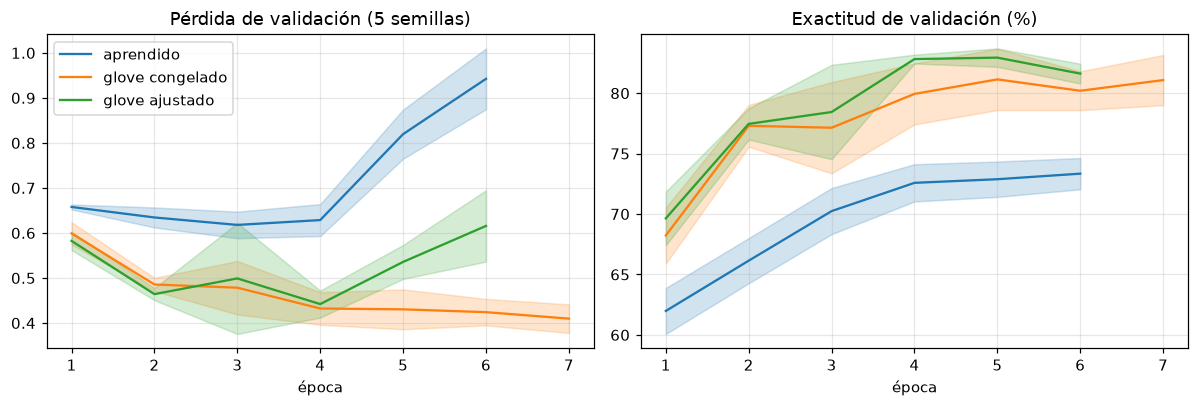

--- aprendido (semilla 0) ---
              precision    recall  f1-score   support

    Negativa      0.743     0.706     0.724      2983
    Positiva      0.723     0.759     0.741      3017

    accuracy                          0.733      6000
   macro avg      0.733     0.733     0.732      6000
weighted avg      0.733     0.733     0.732      6000

--- glove_congelado (semilla 0) ---
              precision    recall  f1-score   support

    Negativa      0.836     0.818     0.827      2983
    Positiva      0.824     0.841     0.832      3017

    accuracy                          0.830      6000
   macro avg      0.830     0.830     0.830      6000
weighted avg      0.830     0.830     0.830      6000

--- glove_ajustado (semilla 0) ---
              precision    recall  f1-score   support

    Negativa      0.807     0.866     0.835      2983
    Positiva      0.857     0.795     0.825      3017

    accuracy                          0.830      6000
   macro avg      0.832    

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
colores = {'aprendido': 'tab:blue', 'glove_congelado': 'tab:orange', 'glove_ajustado': 'tab:green'}
for emb, res in finales.items():
    for clave, eje in (('val_loss', 0), ('val_acc', 1)):
        n = min(len(r[1]['hist'][clave]) for r in res)
        curvas = np.array([r[1]['hist'][clave][:n] for r in res])
        mu, sd = curvas.mean(0), curvas.std(0)
        x = np.arange(1, n + 1)
        ax[eje].plot(x, 100 * mu if eje else mu, color=colores[emb], label=emb.replace('_', ' '))
        ax[eje].fill_between(x, 100 * (mu - sd) if eje else mu - sd, 100 * (mu + sd) if eje else mu + sd,
                             color=colores[emb], alpha=0.2)
ax[0].set_title('Pérdida de validación (5 semillas)'); ax[0].set_xlabel('época'); ax[0].legend()
ax[1].set_title('Exactitud de validación (%)'); ax[1].set_xlabel('época')
plt.tight_layout(); plt.show()

y_test = ETIQUETAS[IDX['test']].numpy()
for emb in OPCIONES:
    p = finales[emb][0][1]['probs_test']
    print(f'--- {emb} (semilla 0) ---')
    print(classification_report(y_test.astype(int), (p > 0.5).astype(int), target_names=['Negativa', 'Positiva'], digits=3))

**Curvas (5 semillas):**

* **Aprendido**: la pérdida de validación es mínima hacia la época 3 y después se dispara (≈ 0,94 en la 6) mientras la exactitud apenas cambia (≈ 73 %). La red se vuelve **demasiado segura** en sus errores: sobreajuste claro.
* **GloVe congelado**: la pérdida de validación sigue bajando lentamente (≈ 0,41 en la época 7). Con solo los pesos de la GRU entrenables, **no sobreajusta** en este horizonte.
* **GloVe ajustado**: llega antes a su mejor punto (época 4) y después también sobreajusta. Dejar entrenar el embedding le da a la red ≈ 1 millón de parámetros más con los que memorizar.
* En el informe por clases, GloVe congelado está **equilibrado** (F1 0,83 en las dos clases). GloVe ajustado tiende a decir «negativa» (*recall* 0,87 en negativas frente a 0,80 en positivas).

**Referencia sin red recurrente.** Una regresión logística sobre TF-IDF de unigramas y bigramas (bolsa de palabras, sin orden), entrenada con las mismas 3 000 reseñas, da una idea de cuánto aporta la LSTM.

In [20]:
textos_tr = [' '.join(TOKENS['sin_stopwords'][i]) for i in IDX['train_0.25']]
textos_te = [' '.join(TOKENS['sin_stopwords'][i]) for i in IDX['test']]
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
logreg = LogisticRegression(C=10, max_iter=2000).fit(tfidf.fit_transform(textos_tr), ETIQUETAS[IDX['train_0.25']].numpy())
acc_tfidf = accuracy_score(y_test, logreg.predict(tfidf.transform(textos_te)))
print(f'TF-IDF (1-2 gramas) + regresión logística, 3000 reseñas: {acc_tfidf:.2%} en test')

TF-IDF (1-2 gramas) + regresión logística, 3000 reseñas: 87.70% en test


**La bolsa de palabras gana: 87,7 %**, 5,6 puntos por encima de la mejor red recurrente (82,1 %). Con solo 3 000 reseñas, el sentimiento se decide sobre todo por **qué palabras aparecen** («waste», «awful», «brilliant»…), y una regresión logística sobre TF-IDF lo aprovecha directamente, con muy pocos parámetros efectivos y sin problemas de optimización. Leer en orden solo compensa con muchos más datos, o con modelos preentrenados que ya traen ese conocimiento. Es una referencia que conviene mirar siempre antes de dar por bueno un modelo recurrente.

# 5. ¿Cuántos datos hacen falta? Aprendido frente a GloVe

La diferencia entre los dos enfoques depende de **cuántas reseñas** hay para entrenar: un embedding aprendido tiene que descubrir el significado de cada palabra solo con esas reseñas, mientras que GloVe ya lo trae de un corpus de 6 000 millones de palabras. Se entrena la configuración final con 250, 500, 1 000, 2 000 y 3 000 reseñas (2 semillas; mismo test).

,aprendido,glove_congelado,glove_ajustado
reseñas de entrenamiento,,,
250,0.5417,0.6639,0.6667
500,0.5531,0.6934,0.6970
1000,0.5812,0.7652,0.7330
2000,0.6482,0.7946,0.8046
3000,0.7246,0.8231,0.8207


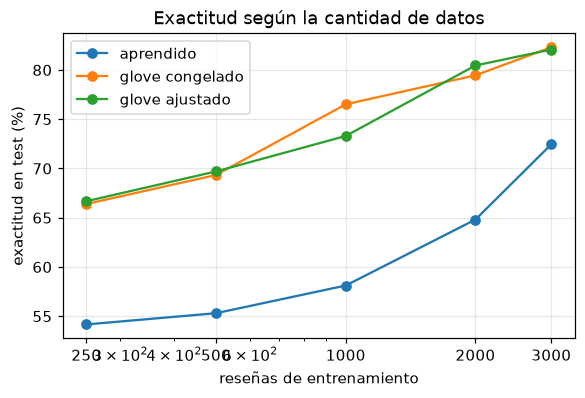

In [21]:
tamaños = (250, 500, 1000, 2000, 3000)
curva_datos = {emb: [np.mean([entrenar(semilla=s, **(CONFIG_FINAL | {'embedding': emb, 'n_train': n}))[1]['test_acc']
                              for s in (0, 1)]) for n in tamaños] for emb in OPCIONES}
display(pd.DataFrame(curva_datos, index=pd.Index(tamaños, name='reseñas de entrenamiento')))
plt.figure(figsize=(6, 3.6))
for emb, accs in curva_datos.items():
    plt.plot(tamaños, 100 * np.array(accs), 'o-', color=colores[emb], label=emb.replace('_', ' '))
plt.xscale('log'); plt.xticks(tamaños, tamaños)
plt.xlabel('reseñas de entrenamiento'); plt.ylabel('exactitud en test (%)'); plt.legend()
plt.title('Exactitud según la cantidad de datos'); plt.show()

**Exactitud en test según el número de reseñas de entrenamiento** (2 semillas):

| Reseñas | Aprendido | GloVe congelado | GloVe ajustado |
|---|---|---|---|
| 250 | 54,2 % | 66,4 % | 66,7 % |
| 500 | 55,3 % | 69,3 % | 69,7 % |
| 1 000 | 58,1 % | 76,5 % | 73,3 % |
| 2 000 | 64,8 % | 79,5 % | 80,5 % |
| 3 000 | 72,5 % | 82,3 % | 82,1 % |

* Con 250–500 reseñas, el **embedding aprendido apenas supera el azar** (54–55 %). GloVe ya acierta dos de cada tres: trae el significado de las palabras de un corpus enorme.
* **GloVe congelado con 1 000 reseñas (76,5 %) supera al aprendido con 3 000 (72,5 %).**
* La ventaja de GloVe es máxima con 1 000 reseñas (+18 puntos) y se reduce a ≈ 10 con 3 000. La curva del aprendido sigue subiendo con fuerza: con muchos más datos la diferencia se seguiría estrechando.
* Ajustar GloVe no da una ventaja clara con ningún tamaño.

# 6. Reseñas cercanas al umbral

El modelo da una **probabilidad**; la decisión es «positiva» si supera 0,5. Las reseñas con probabilidad cerca de 0,5 son aquellas en las que el modelo **duda**. Se usan los modelos de la semilla 0 de la comparación final.

## 6.1. Distribución de probabilidades y exactitud según la confianza

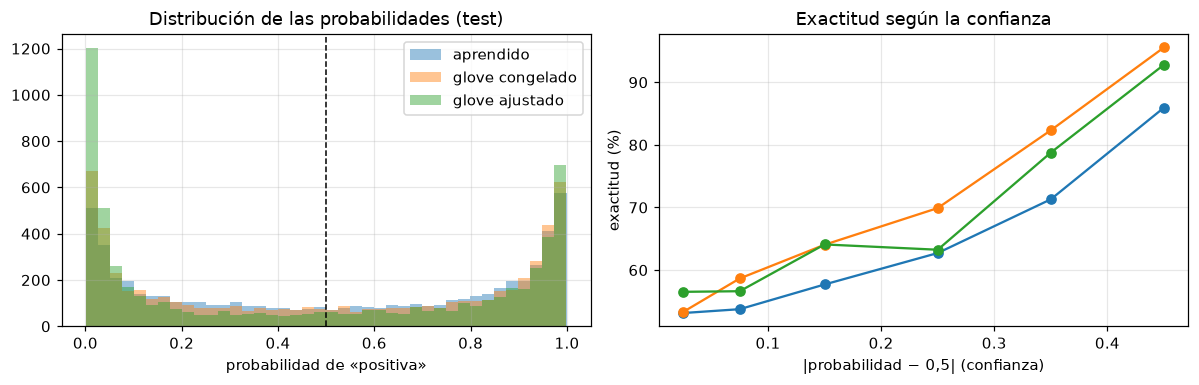

aprendido        reseñas con p en (0,4; 0,6): 10.4% | exactitud en ellas: 53.5% | exactitud en el resto: 75.6%
glove_congelado  reseñas con p en (0,4; 0,6): 10.0% | exactitud en ellas: 55.8% | exactitud en el resto: 86.0%
glove_ajustado   reseñas con p en (0,4; 0,6):  7.5% | exactitud en ellas: 56.6% | exactitud en el resto: 85.2%

reseñas en que discrepan aprendido y GloVe ajustado: 25.7%


In [22]:
probs = {emb: finales[emb][0][1]['probs_test'] for emb in OPCIONES}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for emb, p in probs.items():
    ax[0].hist(p, bins=40, alpha=0.45, color=colores[emb], label=emb.replace('_', ' '))
ax[0].axvline(0.5, color='k', ls='--', lw=1); ax[0].set_xlabel('probabilidad de «positiva»')
ax[0].set_title('Distribución de las probabilidades (test)'); ax[0].legend()
bordes = np.array([0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5])
for emb, p in probs.items():
    dist = np.abs(p - 0.5)
    accs = [((p > 0.5) == y_test)[(dist >= a) & (dist < b + 1e-9)].mean() for a, b in zip(bordes[:-1], bordes[1:])]
    ax[1].plot((bordes[:-1] + bordes[1:]) / 2, 100 * np.array(accs), 'o-', color=colores[emb], label=emb.replace('_', ' '))
ax[1].set_xlabel('|probabilidad − 0,5| (confianza)'); ax[1].set_ylabel('exactitud (%)')
ax[1].set_title('Exactitud según la confianza'); plt.tight_layout(); plt.show()

franja = {emb: (np.abs(p - 0.5) < 0.1) for emb, p in probs.items()}
for emb, m in franja.items():
    print(f'{emb:16} reseñas con p en (0,4; 0,6): {m.mean():5.1%} | exactitud en ellas: {((probs[emb] > 0.5) == y_test)[m].mean():.1%}'
          f' | exactitud en el resto: {((probs[emb] > 0.5) == y_test)[~m].mean():.1%}')
desacuerdo = (probs['aprendido'] > 0.5) != (probs['glove_ajustado'] > 0.5)
print(f'\nreseñas en que discrepan aprendido y GloVe ajustado: {desacuerdo.mean():.1%}')

* La distribución tiene forma de **U**: casi todas las reseñas reciben una probabilidad cercana a 0 o a 1. El modelo GloVe ajustado es el más extremo (≈ 1 200 reseñas por debajo de 0,025).
* Solo el **7,5–10 %** de las reseñas cae en la franja dudosa (0,4–0,6), y **ahí el modelo acierta lo mismo que una moneda**: 53,5 % (aprendido), 55,8 % (GloVe congelado), 56,6 % (GloVe ajustado). Fuera de la franja, 75,6 %, 86,0 % y 85,2 %.
* La exactitud **crece de forma monótona con la confianza**: con GloVe congelado supera el 95 % cuando la probabilidad está a más de 0,4 del umbral. La probabilidad del modelo es una medida útil de su fiabilidad.
* El aprendido y GloVe ajustado **discrepan en el 25,7 %** de las reseñas: no han aprendido lo mismo.

## 6.2. Las reseñas más dudosas, leídas

Las 6 reseñas del test con la probabilidad más cercana a 0,5 según el modelo GloVe ajustado, con lo que dicen los otros dos modelos. Se muestran el principio y el final de cada reseña (el modelo ve los primeros tokens hasta la longitud máxima).

In [23]:
textos_test = imdb_df.loc[IDX['test'], 'text'].tolist()
def resumir(t, n=260):
    t = re.sub(r'<[^>]+>', ' ', t)
    return t if len(t) <= 2 * n else t[:n] + ' […] ' + t[-n:]

orden = np.argsort(np.abs(probs['glove_ajustado'] - 0.5))[:6]
for k, i in enumerate(orden, 1):
    print(f"[{k}] real: {'POSITIVA' if y_test[i] else 'NEGATIVA'} | p(positiva): "
          + ' · '.join(f"{emb.replace('_', ' ')} {probs[emb][i]:.2f}" for emb in OPCIONES)
          + f" | {len(TOKENS[CONFIG_FINAL['prepro']][IDX['test'][i]])} tokens")
    print('   ', resumir(textos_test[i]), '\n')

[1] real: POSITIVA | p(positiva): aprendido 0.24 · glove congelado 0.39 · glove ajustado 0.50 | 274 tokens
    Kennedy-Miller could hardly have done a better job at tackling a very challenging exercise: making dry political events work as human drama, and providing an even-handed representation of explosively controversial subject matter.  The key to its success on the […] sion, Chubb said something along the lines of: "drug bust in Bali, eh?". Obviously this line no longer rings true in the wake of the Schapelle Corby case, which dramatically illustrated that those busted for drugs in Bali can expect far worse than deportation. 

[2] real: POSITIVA | p(positiva): aprendido 0.54 · glove congelado 0.44 · glove ajustado 0.50 | 327 tokens
    I have been most fortunate this year to have seen several films at my university's art museum. On occasion, well, more like half of the time, I am unable to watch the films there. I have systematically attempted to view each of the films that I have 

**Por qué dudan** (las seis son las más cercanas a 0,5 para GloVe ajustado):

1. **Positiva expresada con negaciones** y mucho resumen del argumento: «could hardly have done a better job». Las palabras sueltas («hardly», «controversial», «busted», «drugs») suenan negativas.
2. **Positiva con el elogio al final y truncada**: 327 tokens, de los que la red solo ve los 200 primeros, y el principio es un preámbulo sobre el museo de la universidad.
3. **Positiva corta y con vocabulario engañoso**: «This is **not** the stuff of soap-operas… characters trying to cope but **not** quite succeeding». El elogio es indirecto («a testament to…»).
4. **Mixta**: «it's awesome. **But** … too much talk…», y después datos sobre el reparto. El aprendido la da por negativa (0,05).
5. **Negativa irónica**: «the least scary film… If you havent seen this film **i recommend you do**, its far too funny to be taken seriously». El aprendido cae en la trampa (0,76).
6. **Positiva sobre un videojuego de terror**: «the best horror game». El vocabulario de terror («horrific», «evil») confunde; GloVe congelado acierta (0,91) y el aprendido falla (0,08).

Las dudas vienen de **reseñas mixtas, ironía, elogios expresados con negaciones, resúmenes del argumento y textos truncados**: justo lo que una lectura «palabra a palabra» no resuelve.

## 6.3. Reseñas escritas a mano

Las dos reseñas del código original y otras pensadas para poner a prueba las negaciones, el contraste y la ironía.

In [24]:
def p_positiva(modelo, texto, cfg=CONFIG_FINAL):
    w2i = VOCABS[cfg['prepro']]
    ids = [w2i.get(w, 1) for w in preprocesar(texto, cfg['prepro'])][:cfg['L']] or [1]
    return predecir(modelo, torch.tensor([ids]), torch.tensor([len(ids)])).item()

propias = [positive_review, neg_review,
           'The movie was not good.',
           'The movie was not bad at all, I actually enjoyed it.',
           'Great actors, beautiful photography, but the story is boring and far too long.',
           'Boring at first, but the second half is brilliant and the ending is perfect.',
           'Oh great, another two hours of my life I will never get back.',
           'I expected a masterpiece. I got a mess.']
modelos_finales = {emb: finales[emb][0][0] for emb in OPCIONES}
modelos_finales['original (GloVe congelado)'] = None
tabla_propias = pd.DataFrame({emb.replace('_', ' '): [p_positiva(m, t) if m is not None else
                                                      predict_sentiment(t, originales['GloVe congelado (como se entrega)']['modelo'],
                                                                        word2idx, MAX_LENGTH, device)[1] for t in propias]
                              for emb, m in modelos_finales.items()}, index=[t[:70] for t in propias])
display(tabla_propias.style.format('{:.2f}').background_gradient(cmap='RdYlGn', vmin=0, vmax=1))

,aprendido,glove congelado,glove ajustado,original (GloVe congelado)
This movie was fantastic! The acting was superb and the plot was gripp,0.35,0.98,0.85,0.72
What a waste of time. The plot was predictable and the acting was terr,0.01,0.01,0.01,0.15
The movie was not good.,0.36,0.52,0.48,0.57
"The movie was not bad at all, I actually enjoyed it.",0.07,0.27,0.13,0.39
"Great actors, beautiful photography, but the story is boring and far t",0.70,0.45,0.44,0.88
"Boring at first, but the second half is brilliant and the ending is pe",0.12,0.06,0.13,0.36
"Oh great, another two hours of my life I will never get back.",0.06,0.61,0.83,0.75
I expected a masterpiece. I got a mess.,0.37,0.13,0.14,0.29


**Reseñas escritas a mano** (probabilidad de «positiva»):

* Las dos del código original: los tres modelos aciertan la negativa (0,01). La positiva la aciertan GloVe congelado (0,98) y GloVe ajustado (0,85), pero **el aprendido falla** (0,35).
* **Negaciones**: «The movie was **not good**» queda en la zona de duda (0,36–0,52), y «**not bad** at all, I actually enjoyed it» sale **negativa en los tres** (0,07–0,27). Aunque ahora la palabra «not» llega a la red, con 3 000 reseñas no aprende a **componerla** con la palabra siguiente: domina el peso de «bad».
* **Contraste con «but»**: «Boring at first, **but** the second half is brilliant and the ending is perfect» sale negativa en los tres (0,06–0,13): pesa más «boring» que «brilliant» y «perfect». La reseña con elogios y crítica al final queda en duda con GloVe (0,44–0,45).
* **Ironía**: «Oh great, another two hours of my life I will never get back» sale **positiva** con GloVe (0,61 y 0,83) por «great». El aprendido acierta (0,06).
* «I expected a masterpiece. I got a mess.» → negativa en los tres (0,13–0,37), correcto.

**Conclusión**: en la práctica, los modelos se comportan como una **suma ponderada de palabras con carga de sentimiento**. No aprovechan el orden para entender negaciones, contrastes o ironía; para eso harían falta muchos más datos. Por eso una regresión logística sobre TF-IDF, que hace exactamente eso, les gana.

# 7. ¿Qué han aprendido los embeddings?

Para cada palabra se buscan sus **vecinas más cercanas** (similitud del coseno) en tres espacios: el embedding aprendido desde cero, GloVe original y GloVe tras el ajuste.

In [25]:
def vecinas(matriz, w2i, palabra, k=6):
    i2w = {i: w for w, i in w2i.items()}
    E = F.normalize(matriz.detach().cpu(), dim=1)
    sim = E @ E[w2i[palabra]]
    sim[:2] = -1; sim[w2i[palabra]] = -1
    return ', '.join(i2w[int(j)] for j in sim.topk(k).indices)

w2i_final = VOCABS[CONFIG_FINAL['prepro']]
espacios = {'aprendido': modelos_finales['aprendido'].embedding.weight,
            'GloVe original': MATRICES_GLOVE[CONFIG_FINAL['prepro']],
            'GloVe ajustado': modelos_finales['glove_ajustado'].embedding.weight}
filas = {p: {k: vecinas(E, w2i_final, p) for k, E in espacios.items()}
         for p in ('good', 'bad', 'excellent', 'awful', 'boring', 'waste', 'not') if p in w2i_final}
display(pd.DataFrame(filas).T)

E_glove = F.normalize(MATRICES_GLOVE[CONFIG_FINAL['prepro']], dim=1)
cos = lambda a, b: float(E_glove[w2i_final[a]] @ E_glove[w2i_final[b]])
print(f"GloVe: coseno(good, bad) = {cos('good', 'bad'):.2f} | coseno(good, great) = {cos('good', 'great'):.2f} | "
      f"coseno(excellent, terrible) = {cos('excellent', 'terrible'):.2f}")

,aprendido,GloVe original,GloVe ajustado
good,"sophomoric, nu, created, king, lara, overlooked","better, sure, really, kind, very, way","better, really, sure, kind, think, way"
bad,"bird, mj, convenient, robots, panties, engrossing","worse, good, things, too, thing, lot","worse, things, good, thing, too, nothing"
excellent,"particular, senator, firth, marlow, dive, chewing","good, quality, terrific, superb, best, impressive","good, superb, terrific, quality, best, impressive"
awful,"peyton, prisoners, bull, vanilla, bullitt, fantasy","horrible, terrible, dreadful, horrendous, scary, unbelievable","horrible, terrible, dreadful, horrendous, ugly, unbelievable"
boring,"followers, sink, stalks, expression, joey, phenomenon","tedious, dull, bored, funny, stupid, downright","tedious, dull, stupid, bored, downright, silly"
waste,"ideals, annette, per, problematic, theater, seasoned","wastes, garbage, toxic, trash, dump, water","wastes, garbage, trash, toxic, dump, rubbish"
not,"misunderstanding, bava, ring, liking, shahid, sarandon","would, could, but, even, might, no","would, could, but, even, might, only"


GloVe: coseno(good, bad) = 0.77 | coseno(good, great) = 0.76 | coseno(excellent, terrible) = 0.32


* **Embedding aprendido**: sus vecinas **no tienen ninguna relación** con la palabra («good» → sophomoric, nu, created, king…). Con 3 000 reseñas y ≈ 1 millón de pesos, cada vector solo se mueve lo justo para separar positivas de negativas en el entrenamiento; el resto es ruido aleatorio. Explica su sobreajuste y su mala generalización.
* **GloVe**: vecinas con sentido semántico («awful» → horrible, terrible, dreadful; «waste» → wastes, garbage, trash). Pero **«good» y «bad» son vecinas** (coseno 0,77, el mismo que «good»–«great», 0,76). GloVe aprende de los **contextos** en que aparece cada palabra, y los antónimos aparecen en los mismos («a ___ movie»). La polaridad no está bien codificada, así que la red recurrente tiene que separarla.
* **GloVe ajustado**: las vecinas **apenas cambian** respecto a GloVe original. Con tasa 0,001 y unas 3 épocas, el ajuste mueve muy poco los vectores, lo que cuadra con que no mejore al congelado.

# 8. Conclusiones

1. **El código original** obtiene 72,2 % (GloVe congelado) y 66,0 % (aprendido). Tiene varios fallos:
   * lee el relleno, y el `<PAD>` de GloVe es un vector aleatorio congelado;
   * las *stopwords* de NLTK borran las negaciones;
   * `<br />` pega palabras y `re.sub` recibe las banderas como `count`;
   * entrena solo con 2 000 reseñas y 5 épocas, sin selección del modelo.
2. **Mejoras**, medidas con 3 semillas en validación: no leer el relleno y `<PAD>` a cero (+4,3 con GloVe), 3 000/1 000 con parada temprana (+3), 200 tokens (+2), conservar negaciones e intensificadores (+1,4 con GloVe, +4,7 con el aprendido) y GRU bidireccional (+2 con GloVe). Con el **mismo test**, GloVe congelado pasa del **72,2 % al 82,0 % ± 0,5**.
3. **Aprendido frente a GloVe**: GloVe gana por **11 puntos** (82,0 % frente a 71,1 %), sobre todo con pocos datos: con 1 000 reseñas ya supera al aprendido con 3 000. El aprendido sobreajusta enseguida y su espacio de embedding no tiene estructura. **Ajustar GloVe no mejora** al congelado (82,1 %) y cuesta 2,6 veces más por época; el congelado entrena 3,2 veces menos parámetros.
4. **Reseñas cercanas al umbral**: son el 7,5–10 %, y en ellas el modelo acierta como el azar. Son reseñas mixtas, irónicas, con elogios expresados mediante negaciones o truncadas. La confianza del modelo es informativa: fuera de la franja dudosa acierta el 85–86 %.
5. **Limitación**: con 3 000 reseñas las redes recurrentes no aprenden a componer negaciones ni contrastes, y una **regresión logística sobre TF-IDF (87,7 %)** les gana. GloVe aporta conocimiento previo de las palabras, pero no de cómo se combinan; para eso harían falta muchos más datos o modelos preentrenados de frases (el camino que llevará a los Transformers).
6. **GRU frente a LSTM**: la GRU rinde algo mejor con GloVe (82,4 % frente a 80,4 % en validación), pero aquí es más lenta, porque la GPU de Apple solo tiene núcleo optimizado para la LSTM.

In [26]:
def a_lista(df):
    return [{'opcion': str(i)} | {k: (None if pd.isna(v) else float(v)) for k, v in fila.items()} for i, fila in df.iterrows()]

resultados = {
    'datos': {'total': len(imdb_df), 'train_original': len(IDX['train_0.5']), 'val_original': len(IDX['val_0.5']),
              'test': len(IDX['test']), 'train': len(IDX['train_0.25']), 'val': len(IDX['val_0.25']),
              'mediana_tokens': float(np.median(longitudes)), 'frac_rellenadas': float((longitudes < MAX_LENGTH).mean()),
              'sin_glove': len(sin_glove), 'vocab_original': vocab_size, 'afectadas_count': afectadas},
    'original': {k: {'test_acc': float(v['test_acc']), 'historial': v['historial']} for k, v in originales.items()},
    'tramos': {str(i): {k: float(v) for k, v in fila.items()} for i, fila in tabla_tramos.iterrows()},
    'experimentos': {k: a_lista(v) for k, v in {'arreglos': exp1, 'longitud': exp2, 'stopwords': exp3,
                                                 'arquitectura': exp4}.items()},
    'config_final': CONFIG_FINAL,
    'final': {emb: {'test_acc': [r[1]['test_acc'] for r in res], 'val_acc': [r[1]['val_acc'] for r in res],
                    'mejor_epoca': [r[1]['mejor_epoca'] for r in res], 'entrenables': res[0][1]['entrenables'],
                    's_epoca': float(np.mean([r[1]['segundos'] / r[1]['epocas'] for r in res]))}
              for emb, res in finales.items()},
    'tfidf': float(acc_tfidf),
    'curva_datos': {'tamaños': list(tamaños), **{k: [float(a) for a in v] for k, v in curva_datos.items()}},
    'umbral': {emb: {'frac_franja': float(franja[emb].mean()),
                     'acc_franja': float(((probs[emb] > 0.5) == y_test)[franja[emb]].mean()),
                     'acc_resto': float(((probs[emb] > 0.5) == y_test)[~franja[emb]].mean())} for emb in OPCIONES},
    'desacuerdo': float(desacuerdo.mean()),
    'propias': {t: {k: float(v) for k, v in fila.items()} for t, fila in tabla_propias.iterrows()},
    'vecinas': filas,
}
with open(LAB_DIR / 'resultados_lab3_imdb.json', 'w', encoding='utf-8') as f:
    json.dump(resultados, f, ensure_ascii=False, indent=1, default=float)
print('Resultados guardados en resultados_lab3_imdb.json')

Resultados guardados en resultados_lab3_imdb.json
